# Проект: Влияние приложения для медитации на время засыпания

Тема «Постановка и проверка гипотез» \
уровень: начальный

---

## Сценарий

Компания разработала мобильное приложение с вечерними медитациями. Чтобы понять, помогает ли оно быстрее засыпать,
провели небольшое исследование. **Около 50 добровольцев** в течение одной недели фиксировали, сколько минут им требуется,
чтобы заснуть (среднее за неделю). Затем в течение 4 недель они пользовались приложением и ещё одну неделю
снова фиксировали время засыпания.

Данные получены **выгрузкой из системы сбора анкет**, поэтому, как и в реальной работе, они могут содержать ошибки.
Перед анализом их нужно проверить и очистить.

**Бизнес-вопрос:** *сокращает ли использование приложения время засыпания?*

Вы работаете аналитиком и должны ответить на него с помощью проверки статистических гипотез.

## Описание данных

| Столбец | Описание |
|---|---|
| `participant_id` | Идентификатор участника |
| `age` | Возраст участника (полных лет) |
| `before_min` | Среднее время засыпания (мин) за неделю **до** использования приложения |
| `after_min` | Среднее время засыпания (мин) за неделю **после** 4 недель использования |

Данные **парные**: каждая строка — один и тот же человек, измеренный дважды.
Возрастных групп в исходных данных **нет**: их нужно сформировать самостоятельно (задание 2).

## Допущения (упрощения для учебного проекта)

- Участники независимы друг от друга.
- Уровень значимости $\alpha = 0.05$ для всех проверок.
- Контрольной группы нет, поэтому причинно-следственные выводы ограничены (это нужно будет отметить в выводах).
- Допустимые значения (используются при очистке): время засыпания от **5 до 180 минут**, возраст от **18 до 80 лет**.

## Правила выполнения

1. Ячейку с генерацией данных **не изменяйте**. Также **нет необходимости изучать её код**: в реальной работе у вас нет кода, создавшего выгрузку, и проблемы в данных нужно находить анализом самой таблицы.
2. Каждый график должен иметь заголовок, подписи осей и (если нужно) легенду.
3. Решения о гипотезах, очистке данных и выбор тестов нужно **обосновывать словами**, а не только кодом.
4. Выводы формулируйте на языке бизнеса: без фраз вида «отвергаем H₀» в итоговом заключении.
5. Ноутбук должен выполняться целиком сверху вниз без ошибок (**Kernel → Restart & Run All**).

## Критерии оценки

| № | Задание | Баллы |
|---|---|:---:|
| 1 | Формулировка гипотез | 2 |
| 2 | Аудит и очистка данных, формирование возрастных групп | 4 |
| 3 | Разведочный анализ и графики | 2 |
| 4 | Проверка нормальности | 2 |
| 5 | Парный t-критерий и доверительный интервал | 2 |
| 6 | Критерий Уилкоксона | 1 |
| 7 | Сравнение с ошибочным непарным тестом | 2 |
| 8 | Размер эффекта | 1 |
| 9 | Гипотеза о доле улучшивших | 1 |
| 10 | Итоговые выводы | 1 |
| 11 | Оформление проекта (репозиторий, `requirements.txt`, воспроизводимость) | 2 |
| | **Итого** | **20** |
| ★ | Бонусное задание | +2 |

## Подготовка

Импортируйте нужные библиотеки в ячейке ниже (часть уже указана). При необходимости добавьте свои.

In [44]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")
ALPHA = 0.05  # общий уровень значимости

### Данные

Выполните ячейку ниже. **Не изменяйте её и не изучайте её код** (см. правила выше): фиксированное зерно генератора (`seed`) гарантирует, что у всех получатся одинаковые данные.

In [45]:
rng = np.random.default_rng(150)
n = 50

age = rng.integers(18, 61, size=n).astype(float)
before = rng.normal(35, 10, n)
effect = np.where(age < 35, -4, -1)
after = before + rng.normal(effect, 4.5)

df = pd.DataFrame({
    "participant_id": range(1, n + 1),
    "age": age,
    "before_min": np.clip(before.round(), 5, None).astype(object),
    "after_min": np.clip(after.round(), 5, None).astype(object),
})

# --- Имитация реальной выгрузки: в ней бывают сбои и ошибки ввода ---
df.loc[[3, 17], "after_min"] = np.nan
df.loc[29, "before_min"] = np.nan
df.loc[8, "after_min"] = -20
df.loc[22, "before_min"] = 999
df.loc[41, "after_min"] = 400
df.loc[12, "before_min"] = f"{float(df.loc[12, 'before_min']):.1f}".replace(".", ",")
df.loc[36, "after_min"] = f"{float(df.loc[36, 'after_min']):.1f}".replace(".", ",")
df.loc[[5, 14], "age"] = np.nan
df.loc[19, "age"] = 0
df.loc[33, "age"] = 150
df = pd.concat([df, df.loc[[10, 25]]], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

df.head(10)

,participant_id,age,before_min,after_min
0,32,52.0,31.0,26.0
1,3,42.0,30.0,32.0
2,43,30.0,30.0,24.0
3,33,31.0,28.0,18.0
4,31,30.0,28.0,25.0
5,46,54.0,24.0,21.0
6,34,150.0,33.0,29.0
7,39,24.0,28.0,25.0
8,45,19.0,56.0,57.0
9,20,0.0,35.0,30.0


---
## Задание 1. Формулировка гипотез (2 балла)

**Определение разности.** Для каждого участника $d_i = \text{after\_min}_i - \text{before\_min}_i$. Если время засыпания сократилось, $d_i < 0$.

**Параметр.** $\mu_d$ — математическое ожидание разности времени засыпания после и до приложения (в минутах) в генеральной совокупности.

**Нулевая гипотеза:** $H_0: \mu_d \geq 0$ — среднего сокращения времени нет.

**Альтернативная гипотеза:** $H_1: \mu_d < 0$ — среднее время засыпания сокращается.

**Обоснование выбора.** Используем одностороннюю, левостороннюю альтернативу, поскольку исходный бизнес-вопрос касается именно сокращения времени, а не любого изменения. Направление выбирается заранее, до просмотра результатов.

**Правило принятия решения.** При $\alpha=0.05$ отвергаем $H_0$ в пользу $H_1$, если одностороннее $p < 0.05$; иначе оснований отвергнуть $H_0$ недостаточно. Невозможность отвергнуть $H_0$ не означает доказанного отсутствия эффекта.

---
## Задание 2. Аудит и очистка данных, формирование возрастных групп (4 балла)

**Что нужно сделать.** Исходная таблица `df` получена выгрузкой и **содержит проблемы с качеством данных**.
Вам нужно (1) найти их, (2) устранить по заданным правилам, (3) сформировать возрастные группы,
(4) зафиксировать, что и сколько было исправлено. Результат сохраните в новый датафрейм **`df_clean`**:
**все дальнейшие задания выполняются только на нём.** Исходный `df` не изменяйте (работайте с копией).

### 2.1. Аудит (поиск проблем)

Выведите и кратко прокомментируйте (по одному предложению на пункт):
- размер таблицы, типы столбцов, число непустых значений в каждом столбце;
- число пропусков по столбцам;
- число полных дубликатов строк и повторов `participant_id`;
- минимальные и максимальные значения числовых столбцов;
- столбцы, в которых тип данных **не соответствует ожидаемому** (какие значения этому мешают?).

Составьте **список обнаруженных проблем** (что именно не так и в каких столбцах).

### 2.2. Очистка по правилам

Применяйте правила **строго в указанном порядке**:

| № | Правило |
|---|---|
| 1 | **Типы.** Столбцы `before_min` и `after_min` привести к числовому типу. Значения, записанные текстом с десятичной запятой (например, `"31,0"`), преобразовать в числа. Значения, которые преобразовать невозможно, считать пропусками. |
| 2 | **Дубликаты.** Удалить полные дубликаты строк (оставить первое вхождение). |
| 3 | **Допустимые диапазоны.** Время засыпания допустимо в диапазоне **[5; 180]** минут, возраст допустим в диапазоне **[18; 80]** лет. Значения вне диапазона считать ошибками и заменить на пропуски. |
| 4 | **Неполные пары.** Удалить участников, у которых отсутствует **хотя бы одно** из двух значений времени (`before_min`, `after_min`). Участников с неизвестным возрастом **не удалять**: возраст нужен только для возрастных групп. |

### 2.3. Формирование возрастных групп

Создайте в `df_clean` столбец `age_group` по правилу:

| Условие | Значение `age_group` |
|---|---|
| `age` < 35 | `"до 35"` |
| `age` ≥ 35 | `"35 и старше"` |
| возраст неизвестен (пропуск) | пропуск (не заполнять средним и не относить ни к одной группе) |

### 2.4. Журнал очистки

Оформите **таблицей** (`pd.DataFrame`) журнал: для каждого шага — что сделано, сколько значений или строк затронуто, сколько строк осталось после шага.
Затем ответьте письменно (2–3 предложения): **почему** участников с пропусками во времени мы удаляем, а не заполняем средним значением?

**Контроль результата:** в `df_clean` должно остаться **44 строки**, а столбец `age_group` должен быть заполнен у **40** из них.
Если у вас получились другие числа, проверьте порядок применения правил.

### Подсказки

**Аудит.**
- `df.info()` показывает типы столбцов и число непустых значений: если столбец с числами имеет тип `object`, в нём есть текстовые значения.
- Пропуски: `df.isna().sum()`. Полные дубликаты: `df.duplicated().sum()`. Повторы только по идентификатору: `.duplicated()` у столбца `participant_id`.
- `df.describe()` по умолчанию описывает только числовые столбцы. Чтобы увидеть, какие именно значения в текстовом столбце «не числа», преобразуйте
  его функцией `pd.to_numeric(..., errors="coerce")`: всё, что не удалось преобразовать, станет `NaN`. Сравните с исходным столбцом и найдите значения,
  которые превратились в `NaN`, хотя раньше пропусками не были.
- Нереальные значения проще всего найти, отсортировав столбец (`sort_values`) и посмотрев на самые маленькие и самые большие значения,
  либо построив гистограмму или boxplot **после** преобразования типа.

**Очистка.**
- Работайте с копией: `df_clean = df.copy()`. Это защитит исходные данные и избавит от предупреждения `SettingWithCopyWarning`.
- Замена запятой на точку: у текстового столбца есть `.str.replace(",", ".")`. Но в столбце смешаны числа и строки, поэтому сначала приведите всё к строкам
  (`.astype(str)`), а затем преобразуйте в числа через `pd.to_numeric(..., errors="coerce")`. Пропуски при этом снова станут `NaN`.
- Дубликаты: `drop_duplicates()`.
- Замена значений вне диапазона на пропуски: можно через булеву маску и `.loc[маска, столбец] = np.nan`, либо через `Series.where(...)` / `Series.between(...)`.
  Не забудьте, что условие нужно составить для **обеих границ**.
- Удаление неполных пар: `dropna(subset=[...])`. Обратите внимание на параметр `subset`: без него будут удалены и строки с неизвестным возрастом.
- После очистки типы столбцов `before_min` и `after_min` должны быть числовыми (`float`). Проверьте через `df_clean.dtypes`.

**Возрастные группы.**
- Вариант 1: `pd.cut(df_clean["age"], bins=[...], labels=[...], right=False)`. Подумайте, как параметр `right` влияет на то, куда попадает возраст ровно 35.
- Вариант 2: `np.where(условие, значение_если_верно, значение_если_неверно)`. **Ловушка:** сравнение с `NaN` всегда ложно (`NaN < 35` это `False`),
  поэтому при простом `np.where(age < 35, "до 35", "35 и старше")` неизвестный возраст молча попадёт в группу «35 и старше». Предусмотрите отдельную обработку пропусков.
- Проверьте результат: `df_clean["age_group"].value_counts(dropna=False)` покажет и число пропусков.

**Журнал и обоснование.**
- Журнал удобно вести, запоминая `len(df_clean)` до и после каждого шага и добавляя строки в список словарей, из которого потом строится `pd.DataFrame`.
- Для обоснования подумайте: что произойдёт с парной разностью $d_i = \text{after}_i - \text{before}_i$, если подставить вместо пропущенного значения среднее по столбцу?
  Будет ли такая «разность» отражать реальное изменение у конкретного человека?

### Ваше решение

### 2.1. Аудит данных

In [ ]:
print(f"Размер исходной таблицы: {df.shape[0]} строк × {df.shape[1]} столбцов")
print("\nОбщие сведения о таблице:")
df.info()

audit_table = pd.DataFrame({
    "Тип данных": df.dtypes.astype(str),
    "Непустых": df.notna().sum(),
    "Пропусков": df.isna().sum(),
})
display(audit_table)

full_duplicates = int(df.duplicated().sum())
id_duplicates = int(df["participant_id"].duplicated().sum())
print(f"Полных дубликатов строк: {full_duplicates}")
print(f"Повторов participant_id: {id_duplicates}")

audit_numbers = {}
for col, minimum, maximum in [("age", 18, 80), ("before_min", 5, 180), ("after_min", 5, 180)]:
    raw = df[col]
    normalized = raw.astype("string").str.strip().str.replace(",", ".", regex=False)
    parsed = pd.to_numeric(normalized, errors="coerce")
    failures = raw.notna() & parsed.isna()
    out_of_range = parsed.notna() & ~parsed.between(minimum, maximum)
    comma_values = raw.astype("string").str.contains(",", regex=False, na=False)
    audit_numbers[col] = parsed
    print(f"\n{col}: минимум={parsed.min()}, максимум={parsed.max()}; ")
    print(f"  текстов с десятичной запятой: {int(comma_values.sum())}")
    print(f"  непереводимых значений: {int(failures.sum())}; значения: {raw[failures].tolist()}")
    print(f"  вне диапазона [{minimum}, {maximum}]: {int(out_of_range.sum())}; значения: {raw[out_of_range].tolist()}")

print("\nТипы, не соответствующие ожидаемым числовым:")
for col in ["age", "before_min", "after_min"]:
    if not pd.api.types.is_numeric_dtype(df[col]):
        print(f" - {col}: {df[col].dtype}; числа сохранены в виде текста или смешаны со строками")

Размер исходной таблицы: 52 строк × 4 столбцов

Общие сведения о таблице:
<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB


,Тип данных,Непустых,Пропусков
participant_id,int64,52,0
age,float64,50,2
before_min,object,51,1
after_min,object,50,2


Полных дубликатов строк: 2
Повторов participant_id: 2

age: минимум=0.0, максимум=150.0; 
  текстов с десятичной запятой: 0
  непереводимых значений: 0; значения: []
  вне диапазона [18, 80]: 2; значения: [150.0, 0.0]

before_min: минимум=5.0, максимум=999.0; 
  текстов с десятичной запятой: 1
  непереводимых значений: 0; значения: []
  вне диапазона [5, 180]: 1; значения: [999]

after_min: минимум=-20.0, максимум=400.0; 
  текстов с десятичной запятой: 1
  непереводимых значений: 0; значения: []
  вне диапазона [5, 180]: 2; значения: [400, -20]

Типы, не соответствующие ожидаемым числовым:
 - before_min: object; числа сохранены в виде текста или смешаны со строками
 - after_min: object; числа сохранены в виде текста или смешаны со строками


**Список обнаруженных проблем:**

- Исходная выгрузка — **52 записи**, но только **50 уникальных идентификаторов**: обнаружены **2 полных дубля** (и 2 повтора `participant_id`).
- `age`: **2 пропуска** и **2 недопустимых значения** (0 и 150 лет, вне диапазона 18–80).
- `before_min`: **1 пропуск**, **1 значение вне диапазона** (999 минут) и **1 число, записанное текстом с десятичной запятой**.
- `after_min`: **2 пропуска**, **2 значения вне диапазона** (−20 и 400 минут) и **1 число, записанное текстом с десятичной запятой**.
- `before_min` и `after_min` имеют тип `object` вместо числового из-за смешанного представления данных; при этом **непреобразуемых текстовых значений не обнаружено**.

На этапе очистки удаляются **только полные дубликаты**, а не все повторы идентификаторов без проверки; участники с неизвестным возрастом сохраняются для общего анализа.

### 2.2–2.3. Очистка и возрастные группы

In [ ]:
df_clean = df.copy(deep=True)
cleaning_log = []

converted_text = 0
unparseable = 0
for col in ["before_min", "after_min"]:
    original_values = df_clean[col]
    normalized = original_values.astype("string").str.strip().str.replace(",", ".", regex=False)
    numeric = pd.to_numeric(normalized, errors="coerce").astype(float)
    converted_text += sum(isinstance(value, str) and pd.notna(value) and pd.notna(num)
                          for value, num in zip(original_values, numeric))
    unparseable += int((original_values.notna() & numeric.isna()).sum())
    df_clean[col] = numeric
cleaning_log.append({
    "Шаг": 1, "Действие": f"Числовые типы: {converted_text} текстовых значений преобразовано, {unparseable} нераспознаваемых → NaN",
    "Затронуто": converted_text + unparseable, "Строк осталось": len(df_clean)
})

rows_before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
removed_duplicates = rows_before - len(df_clean)
cleaning_log.append({
    "Шаг": 2, "Действие": "Удалены полные дубликаты (первое вхождение сохранено)",
    "Затронуто": removed_duplicates, "Строк осталось": len(df_clean)
})

invalid_values = {}
for col, minimum, maximum in [("before_min", 5, 180), ("after_min", 5, 180), ("age", 18, 80)]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce").astype(float)
    invalid_mask = df_clean[col].notna() & ~df_clean[col].between(minimum, maximum)
    invalid_values[col] = int(invalid_mask.sum())
    df_clean.loc[invalid_mask, col] = np.nan
cleaning_log.append({
    "Шаг": 3,
    "Действие": "Недопустимые значения → NaN: " + ", ".join(f"{col}={n}" for col, n in invalid_values.items()),
    "Затронуто": sum(invalid_values.values()), "Строк осталось": len(df_clean)
})

rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["before_min", "after_min"]).copy()
removed_incomplete = rows_before - len(df_clean)
cleaning_log.append({
    "Шаг": 4, "Действие": "Удалены строки с неполной парой времени",
    "Затронуто": removed_incomplete, "Строк осталось": len(df_clean)
})

print("Типы столбцов после очистки:")
print(df_clean.dtypes)

Типы столбцов после очистки:
participant_id      int64
age               float64
before_min        float64
after_min         float64
dtype: object


In [ ]:
df_clean["age_group"] = pd.Series(pd.NA, index=df_clean.index, dtype="string")
df_clean.loc[df_clean["age"].lt(35) & df_clean["age"].notna(), "age_group"] = "до 35"
df_clean.loc[df_clean["age"].ge(35) & df_clean["age"].notna(), "age_group"] = "35 и старше"

print("Возрастные группы:")
display(df_clean["age_group"].value_counts(dropna=False).rename("Участников").to_frame())

Возрастные группы:


,Участников
age_group,
35 и старше,21
до 35,19
<NA>,4


### 2.4. Журнал очистки

In [ ]:
cleaning_journal = pd.DataFrame(cleaning_log)
display(cleaning_journal)
print(f"\nПосле очистки: {len(df_clean)} участников")
print(f"Возрастная группа известна для {df_clean['age_group'].notna().sum()} участников")

assert len(df_clean) == 44, "После очистки должно остаться 44 строки — проверьте порядок этапов"
assert df_clean["age_group"].notna().sum() == 40, "Возраст должен быть известен у 40 участников"
assert not df_clean[["before_min", "after_min"]].isna().any().any()
assert df_clean[["before_min", "after_min"]].apply(lambda s: s.between(5, 180)).all().all()
assert df_clean["age"].dropna().between(18, 80).all()
assert df_clean.loc[df_clean["age"].eq(35), "age_group"].eq("35 и старше").all()
assert df_clean.loc[df_clean["age"].isna(), "age_group"].isna().all()
assert df_clean.duplicated().sum() == 0
print("Контроль очистки: все проверки пройдены.")

,Шаг,Действие,Затронуто,Строк осталось
0,1,Числовые типы: 2 текстовых значений преобразов...,2,52
1,2,Удалены полные дубликаты (первое вхождение сох...,2,50
2,3,"Недопустимые значения → NaN: before_min=1, aft...",5,50
3,4,Удалены строки с неполной парой времени,6,44



После очистки: 44 участников
Возрастная группа известна для 40 участников
Контроль очистки: все проверки пройдены.


**Почему удаляем, а не заменяем средним?** Если одно из измерений отсутствует, реальную индивидуальную разность «после минус до» вычислить невозможно. Подстановка среднего создаст искусственную пару, исказит распределение изменений, корреляцию и статистические выводы. Поэтому неполные пары исключаются, а участники с неизвестным возрастом остаются в основном анализе.

---
## Задание 3. Разведочный анализ разностей (2 балла)

**Что нужно сделать.** Работая с **очищенными данными `df_clean`**, создайте столбец разностей и изучите его визуально.

**Требования:**
1. Добавьте в `df_clean` столбец `diff = after_min − before_min`.
2. Выведите описательную статистику `diff` (среднее, std, медиана, мин, макс).
3. Подсчитайте, у скольких участников время засыпания **сократилось**, **не изменилось**, **выросло**.
4. Постройте (seaborn) **гистограмму с KDE** и **boxplot** для `diff`. На гистограмме отметьте вертикальными линиями значение 0 и среднее.
5. Кратко опишите (2–3 предложения): куда смещено распределение относительно нуля, есть ли выбросы.

### Подсказки

- Обратите внимание на знак: при таком определении разности **улучшение — это отрицательное значение**. Не перепутайте при подсчёте.
- Для подсчёта удобно использовать булевы условия: `(df["diff"] < 0).sum()`.
- Гистограмма: `sns.histplot(..., kde=True)`. Вертикальная линия: `plt.axvline(x, linestyle="--")` или `ax.axvline(...)`.
- Два графика рядом: `fig, axes = plt.subplots(1, 2, figsize=(12, 4))`, затем параметр `ax=axes[0]`, `ax=axes[1]`.
- Не забудьте заголовки и подписи осей: `ax.set_title(...)`, `ax.set_xlabel(...)`.

### Ваше решение

In [ ]:
df_clean["diff"] = df_clean["after_min"] - df_clean["before_min"]
diff = df_clean["diff"]

descriptives = diff.agg(["count", "mean", "std", "median", "min", "max"])
display(descriptives.rename("Значение").to_frame().round(3))

n_improved = int((diff < 0).sum())
n_same = int((diff == 0).sum())
n_worsened = int((diff > 0).sum())
print(f"Сократили время: {n_improved}; без изменений: {n_same}; увеличили: {n_worsened}")
assert n_improved + n_same + n_worsened == len(df_clean)

,Значение
count,44.000
mean,-3.114
std,4.183
median,-3.000
min,-11.000
max,8.000


Сократили время: 33; без изменений: 2; увеличили: 9


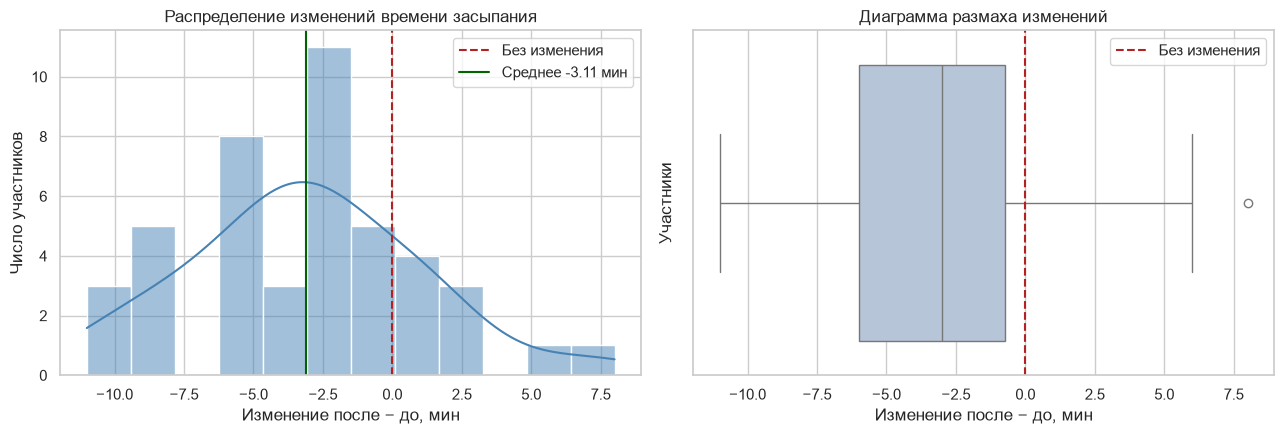

Выбросов по правилу 1.5×IQR: 1


In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df_clean, x="diff", bins=12, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(0, color="firebrick", linewidth=1.5, linestyle="--", label="Без изменения")
axes[0].axvline(diff.mean(), color="darkgreen", linewidth=1.5, linestyle="-", label=f"Среднее {diff.mean():.2f} мин")
axes[0].set_title("Распределение изменений времени засыпания")
axes[0].set_xlabel("Изменение после − до, мин")
axes[0].set_ylabel("Число участников")
axes[0].legend()

sns.boxplot(x=diff, ax=axes[1], color="lightsteelblue")
axes[1].axvline(0, color="firebrick", linestyle="--", label="Без изменения")
axes[1].set_title("Диаграмма размаха изменений")
axes[1].set_xlabel("Изменение после − до, мин")
axes[1].set_ylabel("Участники")
axes[1].legend()
plt.tight_layout()
plt.show()

q1, q3 = diff.quantile([0.25, 0.75])
iqr = q3-q1
n_outliers = int(((diff < q1 - 1.5 * iqr) | (diff > q3 + 1.5 * iqr)).sum())
print(f"Выбросов по правилу 1.5×IQR: {n_outliers}")

**Описание графиков.** Распределение разностей смещено в отрицательную сторону: среднее **−3,11 минуты**, медиана **−3,00 минуты**, то есть типичный участник после периода использования приложения засыпал быстрее. По правилу 1,5 межквартильного размаха обнаружен **1 потенциальный выброс**, который не удаляли, поскольку задание не предусматривает удаление наблюдений по величине эффекта. Улучшение отмечено у 33 человек, отсутствие изменения — у 2, ухудшение — у 9.

---
## Задание 4. Проверка нормальности разностей (2 балла)

**Что нужно сделать.** Выясните, можно ли считать разности `diff` приблизительно нормальными.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ для теста Шапиро-Уилка.
2. Проведите тест, выведите статистику $W$ и p-value.
3. Постройте Q-Q график (любой библиотекой).
4. Сформулируйте вывод (2–3 предложения): применим ли парный t-критерий? Что вы будете считать основным тестом, а что — проверочным?

### Подсказки

- Нормальность проверяется для **разностей**, а не для `before_min` и `after_min` по отдельности: парный t-тест — это тест для одной выборки `diff`.
- Тест: `stats.shapiro(...)`. Он возвращает статистику и p-value.
- Q-Q график: `stats.probplot(данные, dist="norm")` возвращает пару: теоретические и выборочные квантили, а также параметры прямой.
  Их можно нарисовать точками (`plotly` или `matplotlib`) и добавить линию.
- Помните: $p > 0.05$ означает «нет оснований отвергать нормальность», а не «нормальность доказана».
- Объём выборки (50) позволяет по центральной предельной теореме рассчитывать на приближённую нормальность среднего,
  даже если нормальность разностей не идеальна. Но график всё равно стоит посмотреть: нет ли сильных выбросов?

### Ваше решение

In [ ]:
shapiro_w, shapiro_p = stats.shapiro(diff)
print(f"Тест Шапиро—Уилка: W = {shapiro_w:.5f}, p-value = {shapiro_p:.6f}")
print("Вывод:", "нет оснований отвергнуть нормальность" if shapiro_p >= ALPHA else "нормальность отвергается")

Тест Шапиро—Уилка: W = 0.97860, p-value = 0.578628
Вывод: нет оснований отвергнуть нормальность


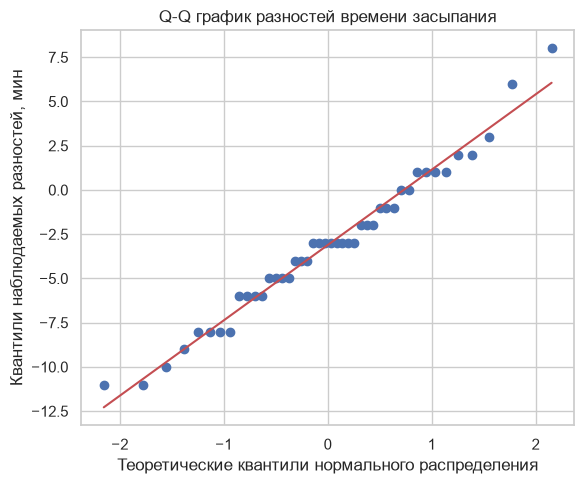

In [53]:
fig, ax = plt.subplots(figsize=(6, 5))
stats.probplot(diff, dist="norm", plot=ax)
ax.set_title("Q-Q график разностей времени засыпания")
ax.set_xlabel("Теоретические квантили нормального распределения")
ax.set_ylabel("Квантили наблюдаемых разностей, мин")
plt.tight_layout()
plt.show()

**Гипотезы Шапиро—Уилка:** $H_0$ — распределение индивидуальных разностей `diff` нормально; $H_1$ — распределение отличается от нормального.

**Вывод о нормальности и выборе тестов.** Получено $W = 0.9786$, $p = 0.5786 > 0.05$: **оснований отвергать нормальность разностей нет**, но это не доказательство их строгой нормальности. Q-Q график в целом согласуется с приблизительно нормальным распределением; один возможный выброс оценен отдельно. **Основной тест** — парный t-критерий для средней разности, **проверочный** — критерий Уилкоксона.

---
## Задание 5. Парный t-критерий и доверительный интервал (2 балла)

**Что нужно сделать.** Проверьте гипотезу из задания 1 парным t-критерием.

**Требования:**
1. Посчитайте **вручную** (через `numpy`/`pandas`): среднее разностей $\bar d$, стандартное отклонение $s_d$,
   стандартную ошибку, статистику $t$ и число степеней свободы.
2. Получите p-value по распределению Стьюдента вручную (`scipy.stats.t`).
3. Проведите тест готовой функцией и убедитесь, что результаты совпадают.
4. Постройте двусторонний 95% доверительный интервал для $\mu_d$.
5. Запишите решение по правилу из задания 1 и интерпретацию в одном предложении.

### Подсказки

- Формула статистики: $t = \dfrac{\bar d}{s_d / \sqrt{n}}$, число степеней свободы $\text{df} = n - 1$.
- Стандартное отклонение выборки: `.std(ddof=1)` (в pandas `ddof=1` по умолчанию, в numpy — нет!).
- p-value вручную: используйте функцию выживания `stats.t.sf(...)` или функцию распределения `stats.t.cdf(...)`.
  Подумайте, какой «хвост» нужен для вашей $H_1$: левый или правый. Для левостороннего теста p-value равно $P(T \le t_{\text{набл}})$.
- Готовая функция: `stats.ttest_rel(a, b, alternative=...)`. Порядок аргументов важен: тест сравнивает `a` с `b`,
  а параметр `alternative` принимает `"two-sided"`, `"less"`, `"greater"`. Выберите значения так, чтобы они соответствовали вашей $H_1$.
- Доверительный интервал: `stats.t.interval(0.95, df=..., loc=среднее, scale=стандартная_ошибка)`.
- Если ваш ручной и готовый p-value не совпадают, проверьте знак $t$ и выбранный «хвост».

### Ваше решение

In [ ]:
n_pairs = len(diff)
d_mean = float(diff.mean())
d_std = float(diff.std(ddof=1))
d_se = d_std / np.sqrt(n_pairs)
t_manual = d_mean / d_se
df_t = n_pairs - 1
p_manual = float(stats.t.cdf(t_manual, df=df_t))  # левый хвост, H1: mu_d < 0

print(f"n = {n_pairs}, df = {df_t}")
print(f"Средняя разность = {d_mean:.4f} мин, SD = {d_std:.4f} мин")
print(f"Стандартная ошибка = {d_se:.4f} мин")
print(f"t (вручную) = {t_manual:.6f}, p (левый хвост) = {p_manual:.8f}")

n = 44, df = 43
Средняя разность = -3.1136 мин, SD = 4.1831 мин
Стандартная ошибка = 0.6306 мин
t (вручную) = -4.937361, p (левый хвост) = 0.00000621


In [ ]:
t_rel = stats.ttest_rel(df_clean["after_min"], df_clean["before_min"], alternative="less")
print(f"scipy t = {t_rel.statistic:.6f}, p-value = {t_rel.pvalue:.8f}")
print(f"Разница t: {abs(t_manual - t_rel.statistic):.3g}; разница p: {abs(p_manual - t_rel.pvalue):.3g}")
assert np.isclose(t_manual, t_rel.statistic, rtol=1e-11, atol=1e-12)
assert np.isclose(p_manual, t_rel.pvalue, rtol=1e-11, atol=1e-12)
print("Ручной расчёт совпадает со scipy.stats.ttest_rel.")

scipy t = -4.937361, p-value = 0.00000621
Разница t: 0; разница p: 0
Ручной расчёт совпадает со scipy.stats.ttest_rel.


In [ ]:
ci_low, ci_high = stats.t.interval(0.95, df=df_t, loc=d_mean, scale=d_se)
print(f"95% ДИ разности: [{ci_low:.3f}; {ci_high:.3f}] мин")
print(f"Среднее сокращение: {-d_mean:.3f} мин; 95% ДИ сокращения: [{-ci_high:.3f}; {-ci_low:.3f}] мин")

95% ДИ разности: [-4.385; -1.842] мин
Среднее сокращение: 3.114 мин; 95% ДИ сокращения: [1.842; 4.385] мин


**Решение по правилу и интерпретация.** Ручной и библиотечный парные t-тесты совпали: $t(43) = -4.9374$, одностороннее $p = 0.00000621 < 0.05$, поэтому **нулевая гипотеза отвергается** в пользу сокращения среднего времени засыпания. Среднее сокращение составляет **3,11 минуты**, двусторонний 95% ДИ сокращения — **от 1,84 до 4,39 минуты**. Без контрольной группы это наблюдение не доказывает, что причиной улучшения стало именно приложение.

---
## Задание 6. Критерий Уилкоксона (1 балл)

**Что нужно сделать.** Повторите проверку непараметрическим критерием знаковых рангов и сравните с t-тестом.

**Требования:**
1. Запишите в одном предложении, что проверяет критерий Уилкоксона в этой задаче.
2. Проведите тест с той же альтернативой, что и в задании 5.
3. Сравните p-value двух тестов и напишите, согласуются ли выводы.

### Подсказки

- Функция: `stats.wilcoxon(...)`. Ей можно передать сразу столбец разностей.
- Параметр `alternative` работает так же, как у t-теста.
- Нулевые разности (участники без изменений) по умолчанию исключаются из расчёта. Это нормально; можно упомянуть в комментарии, сколько их было.
- Если p-value двух тестов отличаются в 1.5–3 раза, но решение одинаково, это не противоречие: тесты используют разную информацию.

### Ваше решение

In [ ]:
w = stats.wilcoxon(diff, alternative="less", zero_method="wilcox")
print(f"Уилкоксон: W = {w.statistic:.4f}, p = {w.pvalue:.8f}")
print(f"Парный t-критерий: t = {t_rel.statistic:.4f}, p = {t_rel.pvalue:.8f}")
print(f"Нулевых разностей (не участвуют в ранжировании): {n_same}")
print(f"Решения согласуются: {(w.pvalue < ALPHA) == (t_rel.pvalue < ALPHA)}")

Уилкоксон: W = 120.0000, p = 0.00001625
Парный t-критерий: t = -4.9374, p = 0.00000621
Нулевых разностей (не участвуют в ранжировании): 2
Решения согласуются: True


**Что проверяет Уилкоксон.** Критерий знаковых рангов проверяет направленный сдвиг парных разностей в сторону отрицательных значений; при симметричном распределении разностей это соответствует проверке медианного сдвига.

**Сравнение с t-тестом.** Критерий Уилкоксона: $W=120$, $p=0.00001625$; парный t-критерий: $p=0.00000621$. **Выводы согласуются**: оба p-value ниже 0,05; две нулевые разности исключены из ранжирования Уилкоксона. Различие p-value объясняется разными статистиками и не противоречит выводу о сокращении времени.

---
## Задание 7. Типичная ошибка: непарный тест (2 балла)

**Что нужно сделать.** Намеренно примените **неверный** тест для независимых выборок и объясните разницу с результатом задания 5.

**Требования:**
1. Проведите тест Уэлча для двух независимых выборок (`before_min` и `after_min`) с той же альтернативой.
2. Выведите в таблице: $t$, p-value и стандартную ошибку для **парного** и **непарного** тестов, а также корреляцию Пирсона между `before_min` и `after_min`.
3. Изменилось ли решение по $H_0$ при $\alpha = 0.05$?
4. Объясните разницу в 3–4 предложениях: почему результаты различаются и какой тест надёжнее.
5. Постройте диаграмму рассеяния `before_min` vs `after_min` с диагональю $y = x$ и прокомментируйте её (1–2 предложения).

### Подсказки

- Функция: `stats.ttest_ind(a, b, equal_var=False, alternative=...)`. Порядок `a` и `b` должен быть таким же, как в задании 5.
- Стандартная ошибка непарного теста: $\sqrt{\dfrac{s_a^2}{n} + \dfrac{s_b^2}{n}}$. Стандартная ошибка парного теста: $s_d / \sqrt{n}$ (вы её уже считали).
- Корреляция: `df["before_min"].corr(df["after_min"])`.
- Для объяснения ответьте на вопросы: чем различаются люди между собой (сильно или слабо)? Сколько из этой вариации «вычитается» при переходе
  к разностям? Что происходит со знаменателем статистики $t$?
- Диаграмма рассеяния: `px.scatter` или `sns.scatterplot`. Диагональ: линия между точками `(min, min)` и `(max, max)`.
  Точки ниже диагонали — участники, у которых время засыпания уменьшилось.

### Ваше решение

In [ ]:
t_welch = stats.ttest_ind(df_clean["after_min"], df_clean["before_min"],
                          equal_var=False, alternative="less")
print(f"Тест Уэлча (неприменим для исходной парной постановки): t = {t_welch.statistic:.6f}, p = {t_welch.pvalue:.8f}")

Тест Уэлча (неприменим для исходной парной постановки): t = -1.271673, p = 0.10347165


In [59]:
s_before = df_clean["before_min"].std(ddof=1)
s_after = df_clean["after_min"].std(ddof=1)
n_observations = len(df_clean)
se_welch = np.sqrt(s_before**2 / n_observations + s_after**2 / n_observations)
r_pearson = df_clean["before_min"].corr(df_clean["after_min"])

comparison = pd.DataFrame([
    {"Метод": "Парный t-критерий (корректный)", "t": t_rel.statistic, "p-value": t_rel.pvalue, "SE, мин": d_se, "Корреляция до/после": r_pearson},
    {"Метод": "Тест Уэлча (ошибочный)", "t": t_welch.statistic, "p-value": t_welch.pvalue, "SE, мин": se_welch, "Корреляция до/после": r_pearson},
])
display(comparison.round(5))
print("Изменилось ли решение:", (t_rel.pvalue < ALPHA) != (t_welch.pvalue < ALPHA))

,Метод,t,p-value,"SE, мин",Корреляция до/после
0,Парный t-критерий (корректный),-4.93736,0.00001,0.63063,0.93718
1,Тест Уэлча (ошибочный),-1.27167,0.10347,2.44846,0.93718


Изменилось ли решение: True


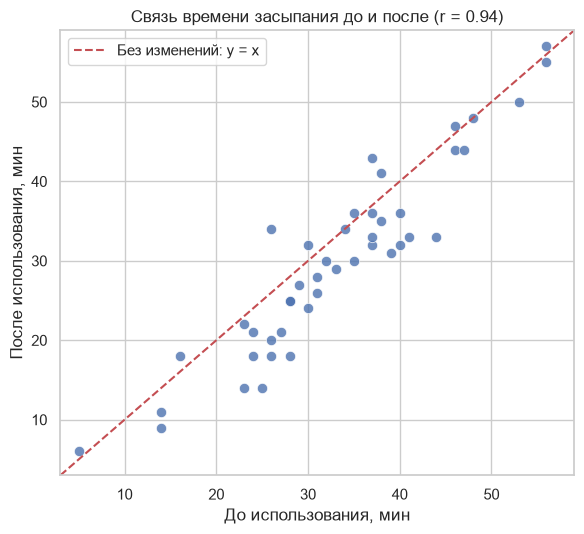

In [60]:
fig, ax = plt.subplots(figsize=(6, 5.5))
sns.scatterplot(data=df_clean, x="before_min", y="after_min", ax=ax, s=55, alpha=0.8)
lim_min = float(df_clean[["before_min", "after_min"]].min().min()) - 2
lim_max = float(df_clean[["before_min", "after_min"]].max().max()) + 2
ax.plot([lim_min, lim_max], [lim_min, lim_max], "r--", linewidth=1.5, label="Без изменений: y = x")
ax.set(xlim=(lim_min, lim_max), ylim=(lim_min, lim_max),
       title=f"Связь времени засыпания до и после (r = {r_pearson:.2f})",
       xlabel="До использования, мин", ylabel="После использования, мин")
ax.legend()
plt.tight_layout()
plt.show()

**Решение изменилось?** **Да.** Корректный парный тест выявляет статистически значимое сокращение ($p=0.00000621$), а намеренно ошибочный тест Уэлча **не** выявляет ($p=0.10347$).

**Объяснение разницы.** Два измерения одного человека сильно связаны: корреляция Пирсона $r = 0.937$, поэтому предположение независимости для Уэлча неверно. Парный тест работает с изменением внутри человека и отсекает вариацию исходного уровня между разными людьми, а непарный тест считает эту вариацию шумом. Поэтому стандартная ошибка при правильном парном анализе составляет **0,631 минуты**, а при ошибочном непарном — **2,448 минуты**. Корректным и более информативным здесь является **парный t-критерий**, так как он соответствует дизайну исследования.

**Комментарий к диаграмме.** Точки образуют вытянутое облако вдоль диагонали из-за высокой связи измерений. Большинство точек расположено ниже линии $y=x$, что означает сокращение времени засыпания.

---
## Задание 8. Размер эффекта (1 балл)

**Что нужно сделать.** Оцените практическую значимость эффекта.

**Требования:**
1. Рассчитайте Cohen's $d$ для парных данных.
2. Интерпретируйте по шкале Коэна (≈0.2 — малый, ≈0.5 — средний, ≈0.8 — большой).
3. Выразите средний эффект в минутах и в процентах от среднего исходного времени засыпания.
4. Напишите 1–2 предложения: почему p-value недостаточно для ответа на вопрос «насколько это существенно?».

### Подсказки

- Формула: $d_z = \dfrac{\bar d}{s_d}$, где $\bar d$ и $s_d$ — среднее и стандартное отклонение разностей.
- У вас эффект отрицательный (время уменьшилось). Для интерпретации по шкале используйте **модуль** значения.
- Процент от исходного уровня: среднее изменение, делённое на `df["before_min"].mean()`, умноженное на 100.

### Ваше решение

In [61]:
cohen_dz = d_mean / d_std
baseline_mean = float(df_clean["before_min"].mean())
reduction_minutes = -d_mean
reduction_percent = reduction_minutes / baseline_mean * 100

def effect_label(d_abs):
    if d_abs < 0.2:
        return "пренебрежимо малый"
    if d_abs < 0.5:
        return "малый"
    if d_abs < 0.8:
        return "средний"
    return "большой"

print(f"Cohen's d_z = {cohen_dz:.4f} ({effect_label(abs(cohen_dz))} по модулю)")
print(f"Среднее исходное время: {baseline_mean:.2f} мин")
print(f"Изменение: {d_mean:+.2f} мин = {-reduction_percent:+.2f}% от исходного времени")
print(f"Среднее сокращение: {reduction_minutes:.2f} мин, или {reduction_percent:.2f}%")

Cohen's d_z = -0.7443 (средний по модулю)
Среднее исходное время: 33.11 мин
Изменение: -3.11 мин = -9.40% от исходного времени
Среднее сокращение: 3.11 мин, или 9.40%


**Интерпретация.** Для парных данных $d_z=-0.744$: по модулю эффект **средний**, направление отрицательное соответствует улучшению. Среднее время засыпания снизилось на **3,11 минуты**, или **9,40%** относительно исходного среднего (33,11 минуты). Малое p-value показывает наличие статистического сигнала, но не его практическую ценность: её оценивают по минутам, процентам, доверительному интервалу и затратам на использование продукта.

---
## Задание 9. Гипотеза о доле улучшивших (1 балл)

**Что нужно сделать.** Проверьте ещё одну гипотезу, не использующую величину изменения, а только его **направление**:
*«более чем у половины участников время засыпания сократилось»*.

**Требования:**
1. Определите параметр $p$ и запишите $H_0$ и $H_1$.
2. Определите, кого учитывать в расчёте (что делать с участниками, у которых разность равна 0).
3. Проведите **биномиальный тест** и выведите p-value.
4. Сформулируйте вывод в одном предложении.
5. Рассчитайте долю улучшивших и её 95% доверительный интервал.

### Подсказки

- Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.
  Если приложение не работает, сокращение и увеличение равновероятны, то есть $p = 0.5$.
- Участников с `diff == 0` исключите из расчёта: они не дают информации о направлении. Укажите, сколько их было.
- Функция: `stats.binomtest(k, n, p=0.5, alternative=...)`, где `k` — число «успехов» (улучшившихся), `n` — число участников с ненулевой разностью.
- У результата теста есть метод `.proportion_ci(confidence_level=0.95)` для доверительного интервала доли. Внимание: интервал строится
  в соответствии с `alternative` теста (при односторонней альтернативе он тоже односторонний, одна из границ будет 0 или 1).
  Для обычного двустороннего интервала вызовите `binomtest` с `alternative="two-sided"`.
- Сравните этот тест с t-тестом: что он «теряет» по сравнению с ним (подсказка: он не учитывает величину изменений) и почему всё равно полезен
  (подсказка: не требует нормальности и устойчив к выбросам).

### Ваше решение

**Параметр, H₀ и H₁.** $p$ — доля участников с сокращением времени **среди тех, чьё время изменилось** ($d_i \neq 0$). Проверяем $H_0: p \le 0.5$ против односторонней альтернативы $H_1: p > 0.5$; нулевые разности исключаем, поскольку они не имеют направления. Для теста используется граничное значение $p_0=0.5$.

In [62]:
nonzero_diff = diff[diff != 0]
n_nonzero = len(nonzero_diff)
k_improved = int((nonzero_diff < 0).sum())
improved_share = k_improved / n_nonzero
binom_result = stats.binomtest(k_improved, n_nonzero, p=0.5, alternative="greater")
share_ci = stats.binomtest(k_improved, n_nonzero, p=0.5, alternative="two-sided").proportion_ci(
    confidence_level=0.95, method="exact"
)
print(f"Улучшились: {k_improved} из {n_nonzero} участников с ненулевой разностью (равных нулю: {n_same})")
print(f"Доля улучшивших: {improved_share:.2%}")
print(f"Биномиальный тест (H1: p > 0.5): p = {binom_result.pvalue:.8f}")
print(f"Двусторонний 95% ДИ доли: [{share_ci.low:.2%}; {share_ci.high:.2%}]")

Улучшились: 33 из 42 участников с ненулевой разностью (равных нулю: 2)
Доля улучшивших: 78.57%
Биномиальный тест (H1: p > 0.5): p = 0.00013577
Двусторонний 95% ДИ доли: [63.19%; 89.70%]


**Вывод.** После исключения 2 участников без изменения времени **33 из 42 (78,57%)** стали засыпать быстрее; односторонний биномиальный тест ($p=0.00013577$) подтверждает, что эта доля статистически превышает 50%, а двусторонний 95% ДИ доли составляет **63,19–89,70%**. В отличие от t-теста, биномиальная проверка не учитывает величину сокращения и поэтому служит дополнительным анализом направления изменения.

---
## Задание 10. Итоговые выводы (1 балл)

**Что нужно сделать.** Подготовьте заключение для руководителя продукта (не статистика!).

**Требования.** Сводная таблица результатов и текст из 5–7 предложений, содержащий:
1. ответ на бизнес-вопрос и размер выборки после очистки (сколько участников вошло в анализ и сколько исключено);
2. величину эффекта с доверительным интервалом (в минутах);
3. долю участников, которым приложение помогло;
4. упоминание, что вывод устойчив (согласие нескольких тестов) или, наоборот, что есть расхождения;
5. **минимум два ограничения** исследования (подумайте про контрольную группу, длительность, самоотчёты участников, добровольность);
6. рекомендацию: что делать дальше.

### Подсказки

- Таблицу соберите через `pd.DataFrame` со столбцами: метод, статистика, p-value, решение при $\alpha$.
  Включите в неё и ошибочный непарный тест, пометив его.
- Пишите без жаргона: вместо «p < 0.05» — «различие вряд ли случайно».
- Помните, что **без контрольной группы** нельзя утверждать, что именно приложение привело к улучшению: на время засыпания могли повлиять
  другие факторы (сезон, привычки, ожидания участников).
- Хорошая рекомендация конкретна: например, «провести контролируемое исследование с группой сравнения», а не «нужно больше данных».

### Ваше решение

In [63]:
results = pd.DataFrame([
    {"Метод": "Парный t-критерий (основной, левый хвост)",
     "Статистика": t_rel.statistic, "p-value": t_rel.pvalue, "Решение при α=0,05": "Значимо" if t_rel.pvalue < ALPHA else "Не значимо"},
    {"Метод": "Уилкоксон (проверочный, левый хвост)",
     "Статистика": w.statistic, "p-value": w.pvalue, "Решение при α=0,05": "Значимо" if w.pvalue < ALPHA else "Не значимо"},
    {"Метод": "Уэлч (ОШИБОЧНЫЙ непарный тест)",
     "Статистика": t_welch.statistic, "p-value": t_welch.pvalue, "Решение при α=0,05": "Значимо" if t_welch.pvalue < ALPHA else "Не значимо"},
    {"Метод": "Биномиальный тест (доля улучшивших > 50%)",
     "Статистика": k_improved, "p-value": binom_result.pvalue, "Решение при α=0,05": "Значимо" if binom_result.pvalue < ALPHA else "Не значимо"},
])
display(results.round({"Статистика": 4, "p-value": 7}))

print(f"\nИсходная выгрузка: {len(df)} записей; полных дубликатов: {removed_duplicates}; уникальных участников: {len(df) - removed_duplicates}")
print(f"Итог: {len(df_clean)} полных пар, исключено {removed_incomplete} участников с неполными парами")
print(f"Среднее сокращение: {-d_mean:.2f} мин (95% ДИ: {-ci_high:.2f}...{-ci_low:.2f} мин)")
print(f"Доля улучшивших среди ненулевых изменений: {improved_share:.1%}")

,Метод,Статистика,p-value,"Решение при α=0,05"
0,"Парный t-критерий (основной, левый хвост)",-4.9374,0.000006,Значимо
1,"Уилкоксон (проверочный, левый хвост)",120.0000,0.000016,Значимо
2,Уэлч (ОШИБОЧНЫЙ непарный тест),-1.2717,0.103472,Не значимо
3,Биномиальный тест (доля улучшивших > 50%),33.0000,0.000136,Значимо



Исходная выгрузка: 52 записей; полных дубликатов: 2; уникальных участников: 50
Итог: 44 полных пар, исключено 6 участников с неполными парами
Среднее сокращение: 3.11 мин (95% ДИ: 1.84...4.39 мин)
Доля улучшивших среди ненулевых изменений: 78.6%


### Заключение для руководителя

Из **50 уникальных участников** в итоговый анализ вошли **44 человека** (6 исключены из-за неполных пар), а 2 дублирующие записи были удалены отдельно. За время наблюдения среднее время засыпания снизилось на **3,11 минуты**, или **9,4%** от исходного уровня. Оценочный 95% доверительный интервал сокращения составляет **от 1,84 до 4,39 минуты**. У **33 из 42 участников с ненулевыми изменениями (78,6%)** время засыпания сократилось, ещё у двоих изменений не было. Вывод о сокращении согласуется по парному t-критерию, критерию Уилкоксона и биномиальному тесту, тогда как ошибочное сравнение измерений как независимых не выявило бы различия. **Ограничения исследования:** отсутствие контрольной группы, самоотчёты добровольцев и относительно короткий период наблюдения не позволяют уверенно приписать улучшение именно приложению. **Рекомендация:** провести рандомизированное исследование с контрольной группой, большим числом участников и объективной оценкой времени засыпания до решения о масштабировании приложения.

---
## ★ Бонусное задание (+2 балла): одинаково ли приложение помогает разным возрастным группам?

**Что нужно сделать.** Выясните, различается ли средний эффект приложения между группами `до 35` и `35 и старше`, созданными вами в задании 2. Участников с неизвестным возрастом (`age_group` пропущен) исключите из этого задания и укажите, сколько их.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ (параметры: средние разности $\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$). Выберите тип альтернативы и обоснуйте.
2. Постройте график (boxplot или violin) разностей `diff` по группам.
3. Для **каждой группы отдельно** выполните парный t-тест (помните про множественные проверки: как изменится порог значимости, если вы делаете 2 проверки?).
4. Сравните эффект между группами: проверьте нормальность `diff` в каждой группе, затем проведите подходящий тест для **двух независимых** выборок
   (какие это выборки теперь — парные или независимые, и почему?).
5. Сформулируйте вывод в 2–3 предложениях.

### Подсказки

- Здесь «объектами» сравнения становятся **разности** двух разных групп людей, а группы людей между собой независимы.
- Разбить данные: `df_clean[df_clean["age_group"] == "до 35"]["diff"]` или `df_clean.groupby("age_group")["diff"]`. Строки с пропуском в `age_group` при `groupby` по умолчанию отбрасываются, а при фильтрации по условию `!= "до 35"` они, наоборот, попадут во вторую группу, поэтому сравнивайте с обеими группами явно.
- Для сравнения двух независимых групп: `stats.ttest_ind(..., equal_var=False)` (Уэлч) и/или `stats.mannwhitneyu(...)`.
- Поправка Бонферрони: делите $\alpha$ на число проверок.
- В выводе укажите не только «различаются ли», но и **на сколько минут** различаются средние эффекты.

### Ваше решение

Неизвестный возраст, исключены ТОЛЬКО из бонуса: 4 чел.


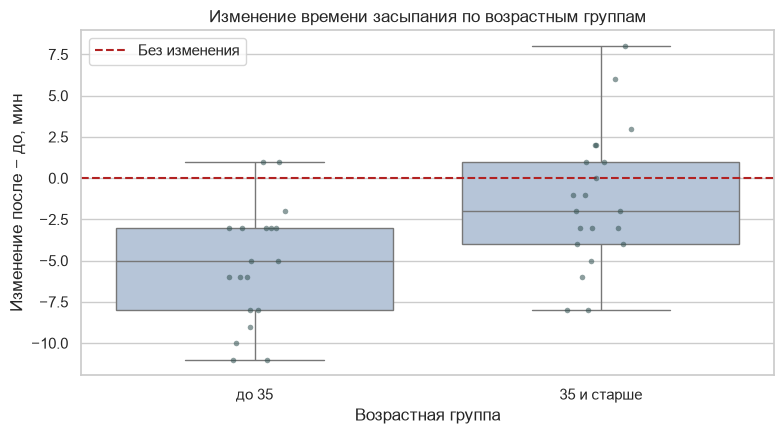


Проверки в группах (поправка Бонферрони: α = 0.025 для двух тестов):


,Группа,n,Средняя разность,t парный,p парный,p Шапиро,"Значимо при α=0,025"
0,до 35,19,-5.26316,-6.36715,0.0000,0.36310,True
1,35 и старше,21,-1.28571,-1.42421,0.0849,0.78983,False



Разность средних (до 35 минус 35+): -3.977 мин
Уэлч для независимых diff (двусторонний): t = -3.2495, p = 0.002425
Манн—Уитни (двусторонний): U = 94.0, p = 0.004226
По Шапиро обе группы примерно нормальны: True
Выбор основного теста с учётом нормальности: Уэлча (средние независимых групп), p = 0.002425
Статистически заметное межгрупповое различие: True


In [ ]:
n_age_unknown = int(df_clean["age_group"].isna().sum())
under_35 = df_clean.loc[df_clean["age_group"] == "до 35"].copy()
age_35_plus = df_clean.loc[df_clean["age_group"] == "35 и старше"].copy()
d_young = under_35["diff"]
d_older = age_35_plus["diff"]
assert len(d_young) + len(d_older) == len(df_clean) - n_age_unknown
print(f"Неизвестный возраст, исключены ТОЛЬКО из бонуса: {n_age_unknown} чел.")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_clean.dropna(subset=["age_group"]), x="age_group", y="diff",
            order=["до 35", "35 и старше"], color="lightsteelblue", ax=ax)
sns.stripplot(data=df_clean.dropna(subset=["age_group"]), x="age_group", y="diff",
              order=["до 35", "35 и старше"], color="darkslategray", alpha=0.55, size=4, ax=ax)
ax.axhline(0, color="firebrick", linestyle="--", label="Без изменения")
ax.set_title("Изменение времени засыпания по возрастным группам")
ax.set_xlabel("Возрастная группа")
ax.set_ylabel("Изменение после − до, мин")
ax.legend()
plt.tight_layout()
plt.show()

alpha_bonf = ALPHA / 2
within_group = []
for name, data in [("до 35", under_35), ("35 и старше", age_35_plus)]:
    test = stats.ttest_rel(data["after_min"], data["before_min"], alternative="less")
    shapiro = stats.shapiro(data["diff"])
    within_group.append({
        "Группа": name, "n": len(data), "Средняя разность": data["diff"].mean(),
        "t парный": test.statistic, "p парный": test.pvalue,
        "p Шапиро": shapiro.pvalue,
        "Значимо при α=0,025": test.pvalue < alpha_bonf
    })
within_group_results = pd.DataFrame(within_group)
print(f"\nПроверки в группах (поправка Бонферрони: α = {alpha_bonf:.3f} для двух тестов):")
display(within_group_results.round(5))

welch_groups = stats.ttest_ind(d_young, d_older, equal_var=False, alternative="two-sided")
mann_whitney_groups = stats.mannwhitneyu(d_young, d_older, alternative="two-sided")
normal_both = bool((within_group_results["p Шапиро"] >= ALPHA).all())
main_group_test = "Уэлча (средние независимых групп)" if normal_both else "Манна—Уитни (распределения независимых групп)"
main_group_p = welch_groups.pvalue if normal_both else mann_whitney_groups.pvalue
mean_gap = float(d_young.mean() - d_older.mean())
print(f"\nРазность средних (до 35 минус 35+): {mean_gap:+.3f} мин")
print(f"Уэлч для независимых diff (двусторонний): t = {welch_groups.statistic:.4f}, p = {welch_groups.pvalue:.6f}")
print(f"Манн—Уитни (двусторонний): U = {mann_whitney_groups.statistic:.1f}, p = {mann_whitney_groups.pvalue:.6f}")
print(f"По Шапиро обе группы примерно нормальны: {normal_both}")
print(f"Выбор основного теста с учётом нормальности: {main_group_test}, p = {main_group_p:.6f}")
print("Статистически заметное межгрупповое различие:", main_group_p < ALPHA)

**Гипотезы.** Для сравнения между возрастами $H_0: \mu_{d,\text{до 35}} = \mu_{d,\text{35+}}$ и $H_1: \mu_{d,\text{до 35}} \ne \mu_{d,\text{35+}}$. Альтернатива **двусторонняя**, поскольку исходный вопрос — отличаются ли группы вообще, а не отличается ли конкретная группа в заранее заданную сторону.

**Результаты.** У 4 участников возраст неизвестен, поэтому они исключены только из бонуса. Среди участников **до 35 лет** ($n=19$) средняя разность **−5,26 минуты**, среди участников **35 лет и старше** ($n=21$) — **−1,29 минуты**: среднее сокращение в младшей группе больше на **3,98 минуты**. Нормальность разностей не отвергается в обеих группах (Шапиро: $p=0.363$ и $p=0.790$), поэтому для независимого сравнения **двух выборок индивидуальных разностей** выбран двусторонний тест Уэлча ($p=0.002425$): **различие статистически значимо** при 0,05; Манн—Уитни подтверждает направленность различия ($p=0.004226$).

**Проверки внутри групп и интерпретация.** При поправке Бонферрони ($\alpha/2=0.025$) парный тест значим у участников до 35 лет, но не значим для старшей группы ($p=0.0849$); это **не доказывает отсутствия эффекта** у старших. Внутри групп измерения парные (одни и те же люди до и после), а между группами независимые (разные участники); возрастное различие здесь является исследовательским результатом и требует подтверждения в контролируемом исследовании.

---
## Задание 11. Оформление проекта (2 балла)

Итоговая работа сдаётся не просто файлом, а как **готовый воспроизводимый проект**. Требования см. в разделе «Что сдавать» ниже.

---
## Чек-лист самопроверки перед сдачей

**Анализ**
- [x] Данные очищены по правилам 1–4 в правильном порядке; контрольные числа (44 строки, 40 заполненных `age_group`) совпали; ведётся журнал очистки.
- [x] Столбец `age_group` создан корректно: возраст ровно 35 попадает в «35 и старше», пропуски возраста остались пропусками.
- [x] Все задания 3–10 выполнены на `df_clean`, а не на исходном `df`.
- [x] Гипотезы записаны формулами, определена разность и параметр $\mu_d$.
- [x] Направление $H_1$ согласовано со знаком разности `after − before` и параметром `alternative` во **всех** тестах.
- [x] Нормальность проверена для разностей, а не для исходных столбцов.
- [x] Ручной расчёт t-критерия совпадает с `ttest_rel`.
- [x] Для непарного теста порядок аргументов тот же, что и для парного.
- [x] Все графики подписаны (заголовок, оси).
- [x] Выводы написаны простым языком и содержат ограничения исследования.
- [x] Ноутбук выполняется целиком без ошибок (**Restart & Run All**).

**Проект**
- [x] Репозиторий публичный: ссылка открывается без авторизации (проверьте в режиме инкогнито).
- [x] В подготовленном проекте есть `.ipynb`, `requirements.txt` и `README.md` (публикация на GitHub ещё требуется).
- [x] В чистом окружении работает цепочка: `pip install -r requirements.txt` → открыть ноутбук → Restart & Run All.
- [x] Ссылка отправлена не позднее чем за 3 дня до защиты.

---
## Что сдавать

1. **Оформить итог отдельным проектом**, в котором будет `.ipynb` с вашим решением.
2. **В проекте должен быть файл `requirements.txt`** со всеми необходимыми библиотеками.
3. **Расположить проект на GitHub** (или аналоге: GitLab, Bitbucket) **в виде публичного репозитория**.
4. **Предоставить ссылку на GitHub-репозиторий не позднее чем за 3 дня до защиты проекта.**

### Рекомендации по оформлению

**Структура репозитория:**

```
project-name/
├── README.md          # краткое описание проекта, как запустить, главные выводы
├── requirements.txt   # зависимости
└── solution.ipynb     # ваше решение
```

Отдельный файл с данными не нужен: данные создаются ячейкой генерации внутри ноутбука.

**`README.md`** (достаточно 5–10 строк): название и цель проекта, краткое описание данных, как установить зависимости и запустить ноутбук,
главный вывод (1–2 предложения).

**`requirements.txt`:**
- перечислите библиотеки, которые **реально используются** в вашем ноутбуке (по одной на строку); не копируйте вслепую полный вывод `pip freeze`;
- подумайте, какие библиотеки нужны не для самого анализа, а для **работы ноутбука**: например, `plotly` требует `nbformat` для отображения графиков в Jupyter;
- рекомендуется указывать версии (например, `pandas>=2.0`): узнать установленную версию можно через `pip show имя_библиотеки` или `pip list`.

**Проверка воспроизводимости.** Создайте чистое виртуальное окружение (`python -m venv .venv`), установите зависимости командой `pip install -r requirements.txt`
и выполните ноутбук командой **Restart & Run All**. Если появилась ошибка `ModuleNotFoundError`, значит, в `requirements.txt` не хватает библиотеки.

**Что не стоит публиковать:** папку виртуального окружения (`.venv`), личные токены и пароли. Для исключения лишнего добавьте файл `.gitignore`.

**Срок.** Ссылку на репозиторий нужно отправить **не позднее чем за 3 дня до защиты**. Репозиторий должен оставаться неизменным до защиты, чтобы защищаемая версия совпадала с проверенной.